In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, r2_score

In [ ]:
data={
'StudyHours':[1,2,2,3,3,4,5,6,7,7,8,9],
'Attendance':[40,50,60,45,55,50,70,75,65,80,85,90],
'Pass':[0,0,0,0,0,0,1,1,1,1,1,1]
}
df=pd.DataFrame(data)
df

,StudyHours,Attendance,Pass
0,1,40,0
1,2,50,0
2,2,60,0
3,3,45,0
4,3,55,0
5,4,50,0
6,5,70,1
7,6,75,1
8,7,65,1
9,7,80,1


### Step 2: Separate Input and Output

In [ ]:
X=df[['StudyHours','Attendance']]
y=df['Pass']

### Step 3: Split Dataset

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(
X,y,test_size=0.25,random_state=42,stratify=y)

### Step 4: Train Model
`kernel='linear'` means the boundary is a straight line.

In [ ]:
model=SVC(kernel='linear',C=1)
model.fit(X_train,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


### Step 5: Predict Test Data

In [ ]:
y_pred=model.predict(X_test)
result=pd.DataFrame({
'Actual':y_test.values,
'Predicted':y_pred
})
print(result)
print("Accuracy:",accuracy_score(y_test,y_pred))

   Actual  Predicted
0       1          1
1       0          0
2       0          0
Accuracy: 1.0


### Step 6: Predict New Student

In [ ]:
new=pd.DataFrame([[6,70]],columns=X.columns)   # 6 hours, 70% attendance
pred=model.predict(new)
print("Prediction:",pred)
print("Result:","Pass" if pred[0]==1 else "Fail")

Prediction: [1]
Result: Pass


### Step 7: Plot Hyperplane, Margin and Support Vectors
- Solid line = **Hyperplane**
- Dashed lines = **Margin**
- Circled points = **Support Vectors**

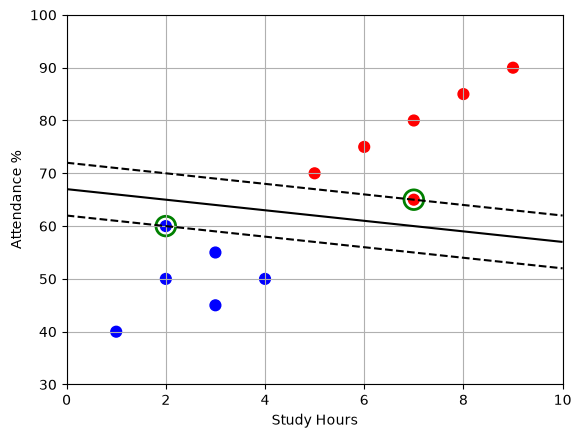

In [ ]:
xx,yy=np.meshgrid(np.linspace(0,10,200),np.linspace(30,100,200))
grid=pd.DataFrame(np.c_[xx.ravel(),yy.ravel()],columns=X.columns)
Z=model.decision_function(grid).reshape(xx.shape)

plt.scatter(df['StudyHours'],df['Attendance'],c=df['Pass'],cmap='bwr',s=60)
plt.contour(xx,yy,Z,levels=[-1,0,1],linestyles=['--','-','--'],colors='k')
plt.scatter(model.support_vectors_[:,0],model.support_vectors_[:,1],
            s=200,facecolors='none',edgecolors='green',linewidths=2)
plt.xlabel("Study Hours")
plt.ylabel("Attendance %")
plt.grid(True)
plt.show()